In [1]:
# Machine Learning Model notebook, housing data in train-data-pseudonymised.csv
# — 1460 rows x 7 predictive features; real rows of train.csv, pseudonymised.
# Pipeline: pick the target (`SalePrice`) -> select 7 predictive features ->
# review `X` -> fit `DecisionTreeRegressor(random_state=1)` on all houses ->
# predict on `X` itself -> split into training and validation data -> refit on
# the training part -> predict the validation part -> score with MAE -> compare
# tree sizes (max_leaf_nodes) for under/overfitting. Charts follow sections
# 1, 2, 3, 4, 8, 10, 11 and 12.
# Run top-to-bottom: cell outputs feed the insight numbers in section 13.


# Imports used across the notebook
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from IPython.display import display

# Chart style: one series colour, grey text, recessive grid, light surface
SERIES = "#2a78d6"      # blue, the main data colour
SERIES_2 = "#eb6834"    # orange, second series (section 12 only)
INK = "#0b0b0b"         # primary text
INK_2 = "#52514e"       # secondary text, reference lines
SURFACE = "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "font.size": 10,
})

# Table style: no fixed text colours, so tables follow the editor's light or
# dark theme; semi-transparent grey borders show on both
RULE = "rgba(128, 128, 128, 0.8)"
LINE = "rgba(128, 128, 128, 0.3)"

def num(v, comma=True):
    """1234.5 -> '1,234.5': at most 2 decimals, trailing zeros dropped."""
    if not pd.api.types.is_number(v) or isinstance(v, bool):
        return v                     # text cells are shown as they are
    text = f"{v:,.2f}" if comma else f"{v:.2f}"
    return text.rstrip("0").rstrip(".")

def styled(df, caption, formats=None, rules_after=(), bold_rows=()):
    """Show df as a formatted table: no index, text columns left-aligned,
    numbers right-aligned. `formats` overrides num per column, `rules_after`
    draws a stronger line under those rows (1 = first row), `bold_rows` sets
    those rows in bold."""
    formats = formats or {}
    # one format call for all columns: a second call would reset the others
    table = df.style.hide(axis="index").format(
        {col: formats.get(col, num) for col in df.columns}, na_rep="")
    styles = [
        {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: bold; white-space: nowrap; padding-bottom: 6px;"},
        {"selector": "th", "props": f"text-align: right; white-space: nowrap; opacity: 0.8; border-bottom: 1.5px solid {RULE}; padding: 4px 12px;"},
        {"selector": "td", "props": f"text-align: right; font-variant-numeric: tabular-nums; white-space: nowrap; border-bottom: 1px solid {LINE}; padding: 4px 12px;"},
    ]
    for j, name in enumerate(df.columns):
        if all(isinstance(v, str) for v in df[name]):    # text column
            styles.append({"selector": f"th.col{j}, td.col{j}", "props": "text-align: left;"})
    for n in rules_after:
        styles.append({"selector": f"tbody tr:nth-child({n}) td", "props": f"border-bottom: 1.5px solid {RULE};"})
    for n in bold_rows:
        styles.append({"selector": f"tbody tr:nth-child({n}) td", "props": "font-weight: bold;"})
    return table.set_caption(caption).set_table_styles(styles)

# Load data
# Path of the file to read
file_path = '../data/train-data-pseudonymised.csv'

home_data = pd.read_csv(file_path)

In [2]:
# 1. Specify Prediction Target (y)
# 2. Create List of Features (X)
# 3. Review List of Features Data
# 4. Specify and Fit Model
# 5. Make Predictions
# 6. Prediction Target Results
# 7. Split Data
# 8. Specify and Fit Model with Training Data
# 9. Make Predictions with Validation Data
# 10. Compare Predictions with Actual Values
# 11. Calculate Mean Absolute Error
# 12. Error vs Tree Size
# 13. Insights

# **1. Specify Prediction Target (y)**


In [3]:
# 1. Specify Prediction Target
# the sale price is the value the model learns to predict
y = home_data.SalePrice

# summary of the prices: range, percentiles, mean and the two most common prices
top2 = y.value_counts().head(2)
rows = [
    ("Houses",                       None,               len(y)),
    ("Lowest price",                 y.min(),            None),
    ("25% of houses sold for under", y.quantile(0.25),   None),
    ("Median (50% sold for under)",  y.median(),         None),
    ("Mean",                         y.mean(),           None),
    ("90% of houses sold for under", y.quantile(0.90),   None),
    ("Highest price",                y.max(),            None),
    ("Standard deviation",           y.std(),            None),
    ("Most common price",            top2.index[0],      top2.iloc[0]),
    ("Second most common price",     top2.index[1],      top2.iloc[1]),
]
price_summary = pd.DataFrame(rows, columns=["Statistic", "Price (USD)", "Houses"])

# formatted table, with lines between the count, the price range and the common prices
styled(price_summary, "Sale prices (SalePrice)", formats={"Price (USD)": "{:,.0f}"},
       rules_after=(1, 8))

Statistic,Price (USD),Houses
Houses,,"1,460"
Lowest price,"34,900",
25% of houses sold for under,"129,975",
Median (50% sold for under),"163,000",
Mean,"180,921",
90% of houses sold for under,"278,000",
Highest price,"755,000",
Standard deviation,"79,443",
Most common price,"140,000",20
Second most common price,"135,000",17


**What this shows:** a summary of the 1,460 sale prices (*SalePrice*), the value
the model learns to predict. They run from 34,900 to 755,000. Half the houses
sold for under 163,000 (the median), but the mean is higher, 180,921, because a
few very expensive houses pull it up. The standard deviation, 79,443, is the
typical distance of a price from the mean: prices vary a lot. Even the most
common price, 140,000, is shared by only 20 houses, so no single price dominates.

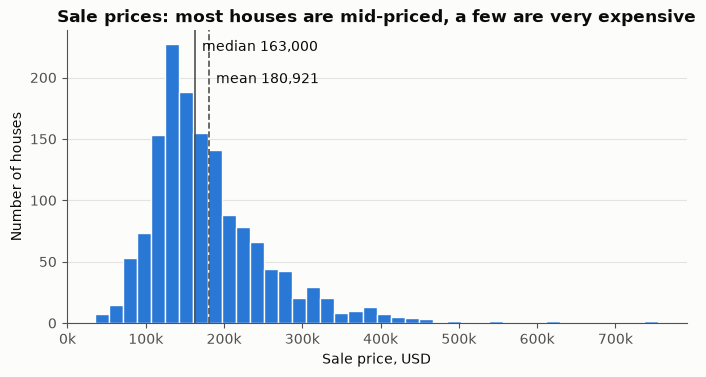

In [4]:
# 1. Chart: how the sale prices are spread
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(y, bins=40, color=SERIES, edgecolor=SURFACE, linewidth=1)
for value, name, style in [(y.median(), "median", "-"), (y.mean(), "mean", "--")]:
    ax.axvline(value, color=INK_2, linewidth=1.2, linestyle=style)
    ax.annotate(f"{name} {value:,.0f}", xy=(value, ax.get_ylim()[1] * (0.93 if name == "median" else 0.82)),
                xytext=(5, 0), textcoords="offset points", color=INK)
ax.set_xlabel("Sale price, USD")
ax.set_ylabel("Number of houses")
ax.set_title("Sale prices: most houses are mid-priced, a few are very expensive")
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k")
ax.grid(axis="x", visible=False)
plt.show()

**What this shows:** how the 1,460 sale prices are spread. Most houses sold for
about 100k–250k, and a thin tail of expensive houses stretches to 755k. That
tail pulls the mean (180,921) above the median (163,000), so the median is the
better picture of a typical house.

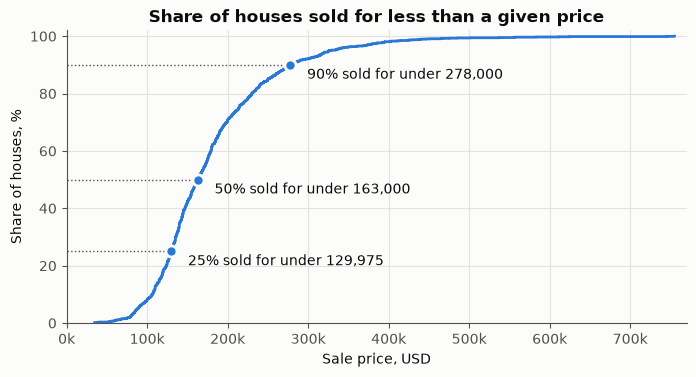

In [5]:
# 1. Chart: share of houses sold for less than a given price
prices = y.sort_values().to_list()
share = [100 * (i + 1) / len(prices) for i in range(len(prices))]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.step(prices, share, where="post", color=SERIES, linewidth=2)
for pct in (25, 50, 90):
    value = y.quantile(pct / 100)
    ax.plot([0, value], [pct, pct], color=INK_2, linewidth=1, linestyle=":")
    ax.plot(value, pct, "o", color=SERIES, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{pct}% sold for under {value:,.0f}", xy=(value, pct),
                xytext=(12, -10), textcoords="offset points", color=INK)
ax.set_xlim(0, y.max() * 1.02)
ax.set_ylim(0, 102)
ax.set_xlabel("Sale price, USD")
ax.set_ylabel("Share of houses, %")
ax.set_title("Share of houses sold for less than a given price")
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k")
plt.show()

**What this shows:** the same 1,460 prices, added up from cheapest to most
expensive. Read it sideways: a quarter of the houses sold for under 129,975,
half for under 163,000 and 90% for under 278,000. The curve is steep in the
middle, where most houses are, and flattens into a long tail up to 755,000:
the last 10% of houses span almost two-thirds of the whole price range.

# **2. Create List of Features (X)**

In [6]:
# 2. Create X
# Create the list of features below
feature_names = ["LotArea", "YearBuilt", "1stFlrSF", "2ndFlrSF",
                 "FullBath", "BedroomAbvGr", "TotRmsAbvGrd"]

# Select data corresponding to features in feature_names
X = home_data[feature_names]

# per feature: its meaning, column type, how many different values it takes
# and how many houses have 0 (for 2ndFlrSF: no second floor)
meanings = ["Lot size, sq ft", "Year built", "First-floor area, sq ft",
            "Second-floor area, sq ft", "Full bathrooms", "Bedrooms above ground",
            "Rooms above ground (no bathrooms)"]
feature_summary = pd.DataFrame({
    "Feature": feature_names,
    "Meaning": meanings,
    "Type": X.dtypes.astype(str).values,
    "Different values": X.nunique().values,
    "Houses at 0": (X == 0).sum().values,
})
styled(feature_summary, "The seven features (X)")

Feature,Meaning,Type,Different values,Houses at 0
LotArea,"Lot size, sq ft",int64,"1,073",0
YearBuilt,Year built,int64,112,0
1stFlrSF,"First-floor area, sq ft",int64,753,0
2ndFlrSF,"Second-floor area, sq ft",int64,417,829
FullBath,Full bathrooms,int64,4,9
BedroomAbvGr,Bedrooms above ground,int64,8,6
TotRmsAbvGrd,Rooms above ground (no bathrooms),int64,12,0


**What this shows:** the seven facts the model may use. All are whole numbers
(*int64*), so the tree can use them as they are, with no conversion. *Different
values* shows how varied each feature is: *LotArea* has 1,073 different lot
sizes, while *FullBath* has only 4. *Houses at 0* flags features where 0 means
"none": 829 houses have no second floor, 9 have no full bathroom and 6 have no
bedroom above ground.

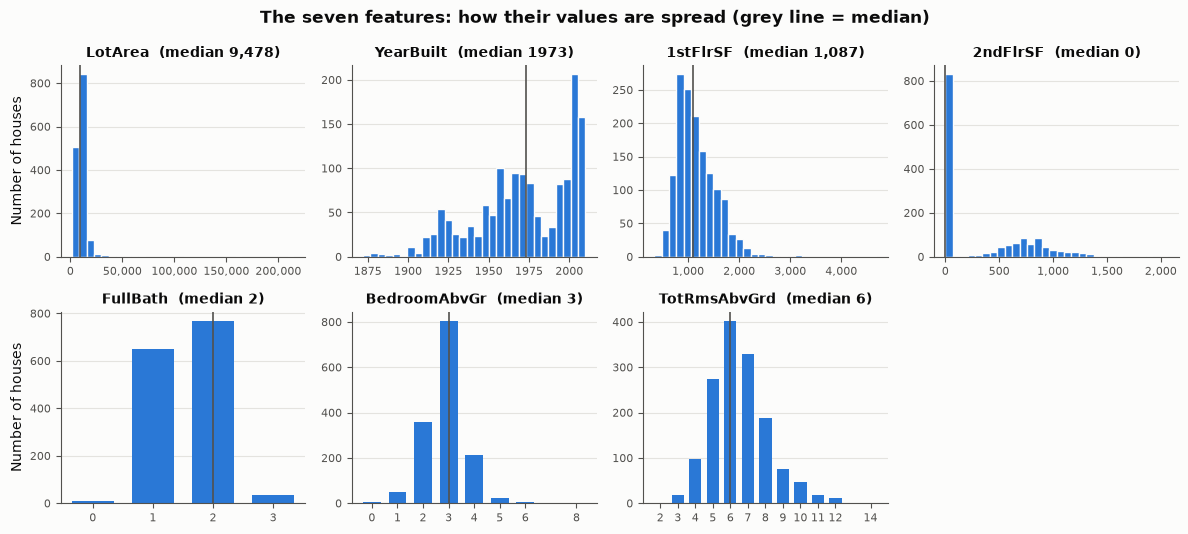

In [7]:
# 2. Chart: how the values of each feature are spread
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4))
for ax, name in zip(axes.flat, feature_names):
    values = X[name]
    if values.nunique() <= 15:
        # few whole-number values: one bar per value
        counts = values.value_counts().sort_index()
        ax.bar(counts.index, counts.values, color=SERIES, width=0.7)
        ax.set_xticks(counts.index)
    else:
        ax.hist(values, bins=30, color=SERIES, edgecolor=SURFACE, linewidth=1)
    ax.axvline(values.median(), color=INK_2, linewidth=1.2)
    fmt = "{:.0f}" if name == "YearBuilt" else "{:,.0f}"   # no comma in years
    ax.set_title(f"{name}  (median {fmt.format(values.median())})", fontsize=10)
    ax.grid(axis="x", visible=False)
    ax.tick_params(labelsize=8)
    ax.xaxis.set_major_formatter(lambda v, _, fmt=fmt: fmt.format(v))
for ax in axes[:, 0]:
    ax.set_ylabel("Number of houses")
axes.flat[-1].axis("off")
fig.suptitle("The seven features: how their values are spread (grey line = median)",
             fontweight="bold")
fig.tight_layout()
plt.show()

**What this shows:** how the 1,460 values of each feature are spread.
*LotArea* has a long tail: most lots are modest, but a few are very large, so
nearly all houses fall into the first few bars. *2ndFlrSF* has a tall bar at 0:
829 houses have no second floor. *FullBath*, *BedroomAbvGr* and *TotRmsAbvGrd*
take only 4, 8 and 12 different values, so they are drawn as separate bars.
*YearBuilt* shows building waves, with the most houses built recently.

# **3. Review List of Features Data**


In [8]:
# 3. Review Data
# statistics of each feature, with its correlation with the target as the last row
stats = X.describe()
stats.loc["correlation"] = X.corrwith(y)
stats = stats.rename(index={"50%": "50% (median)"}).reset_index(names="Statistic")
display(styled(stats, "Feature statistics (last row: correlation with SalePrice)",
               formats={"YearBuilt": lambda v: num(v, comma=False)}, rules_after=(8,)))

# the top few lines
styled(X.head(), "First five houses (X.head())", formats={"YearBuilt": "{}"})

Statistic,LotArea,YearBuilt,1stFlrSF,2ndFlrSF,FullBath,BedroomAbvGr,TotRmsAbvGrd
count,"1,460",1460,"1,460","1,460","1,460","1,460","1,460"
mean,"10,516.83",1971.27,"1,162.63",346.99,1.57,2.87,6.52
std,"9,981.26",30.2,386.59,436.53,0.55,0.82,1.63
min,"1,300",1872,334,0,0,0,2
25%,"7,553.5",1954,882,0,1,2,5
50% (median),"9,478.5",1973,"1,087",0,2,3,6
75%,"11,601.5",2000,"1,391.25",728,2,3,7
max,"215,245",2010,"4,692","2,065",3,8,14
correlation,0.26,0.52,0.61,0.32,0.56,0.17,0.53


LotArea,YearBuilt,1stFlrSF,2ndFlrSF,FullBath,BedroomAbvGr,TotRmsAbvGrd
"8,471",1977,"1,212",0,1,3,6
"9,120",1925,"1,133",687,2,4,8
"13,700",1965,902,918,1,4,8
"8,000",1961,"1,800",0,2,6,10
"10,574",2005,"1,082",871,2,3,9


**What this shows:** the first table describes each feature. *count* is 1,460
everywhere, so no value is missing. *mean* and *50% (median)* describe the
typical house: built around 1973, a first floor of about 1,087 sq ft, 2 full
bathrooms, 3 bedrooms and 6 rooms. The *2ndFlrSF* median is 0, so more than half
the houses have no second floor. *min* and *max* show the range: *LotArea* runs
from 1,300 to 215,245 sq ft, and its mean (10,516.83) sits above its median
(9,478.5) because a few very large lots pull it up. The last row, *correlation*,
is how closely each feature moves with *SalePrice*, from 0 (no link) to 1
(perfect); the chart below draws it as bars. The second table shows the first
five houses as the model sees them: just seven numbers per house.

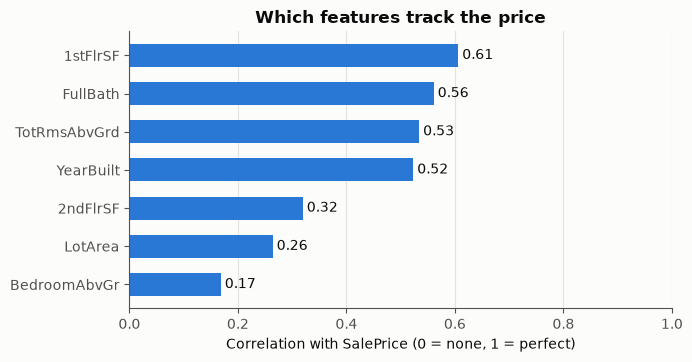

In [9]:
# 3. Chart: how closely each feature moves with the price
corr = X.corrwith(y).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(corr.index, corr.values, color=SERIES, height=0.6)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in corr.values], padding=3, color=INK)
ax.set_xlim(min(0, corr.min() - 0.1), 1)   # left of 0 only if a correlation is negative
ax.set_xlabel("Correlation with SalePrice (0 = none, 1 = perfect)")
ax.set_title("Which features track the price")
ax.grid(axis="y", visible=False)
plt.show()

**What this shows:** how closely each feature moves with *SalePrice*, from 0
(no link) to 1 (perfect). *1stFlrSF*, *FullBath*, *TotRmsAbvGrd* and *YearBuilt*
track price the most; *BedroomAbvGr* the least. No single feature is close to 1,
so the model has to combine them.

# **4. Specify and Fit Model**


In [10]:
# 4. Specify and Fit Model
# Specify the model.
# For model reproducibility, set a numeric value for random_state when specifying the model
model = DecisionTreeRegressor(random_state=1)

# Fit the model
model.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

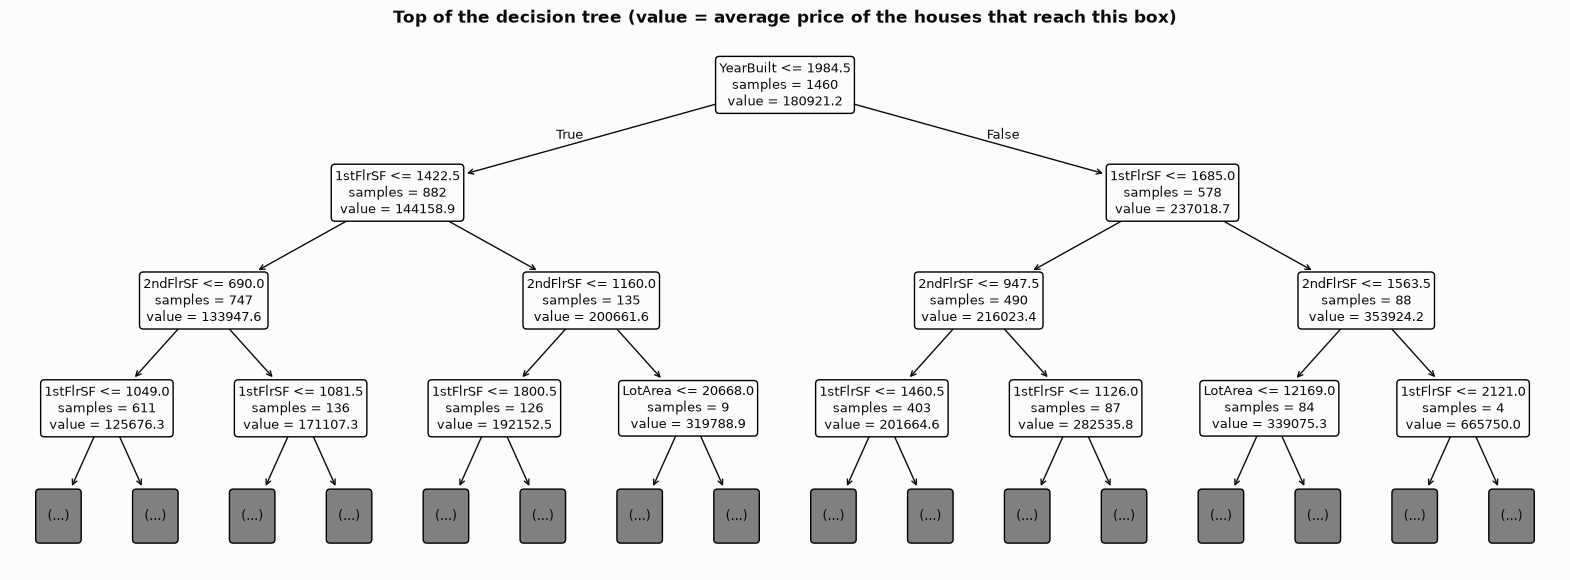

In [11]:
# 4. Chart: the first questions the tree asks (top 3 of its levels)
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(model, max_depth=3, feature_names=feature_names, filled=False,
          impurity=False, rounded=True, precision=1, fontsize=9, ax=ax)
ax.set_title("Top of the decision tree (value = average price of the houses that reach this box)")
plt.show()

**What this shows:** the first three levels of yes/no questions the tree
learned. Its first question splits houses at *YearBuilt* 1984.5; the next ones
use *1stFlrSF* and *2ndFlrSF*, and at the third level *LotArea* joins in. Each
box gives how many houses reach it and their average price: the newest, largest
houses end up in a group of just 4 averaging 665,750. The grey boxes are where
the tree keeps going: it is 23 levels deep in total.

# **5. Make Predictions**


In [12]:
# 5. Make Predictions
predictions = model.predict(X)
print(predictions)

# how closely the tree fits the houses it learned from; every house that misses
# its exact price shares all 7 features with another house (a "twin")
missed = predictions != y
twins = X[missed].index.isin(X[X.duplicated(keep=False)].index).sum()
fit_summary = pd.DataFrame([
    ("Tree depth", model.get_depth()),
    ("Leaves", model.get_n_leaves()),
    ("Exact in-sample matches", f"{(predictions == y).mean() * 100:.1f}%"),
    ("In-sample MAE (USD)", mean_absolute_error(y, predictions)),
    ("Houses not matched exactly", missed.sum()),
    ("of these, with a feature-identical twin", twins),
], columns=["Measure", "Value"])
styled(fit_summary, "How closely the tree fits the houses it learned from", rules_after=(2, 4))

[151000. 184000. 201800. ... 165150. 101800.  82500.]


Measure,Value
Tree depth,23
Leaves,"1,417"
Exact in-sample matches,98.4%
In-sample MAE (USD),62.35
Houses not matched exactly,24
"of these, with a feature-identical twin",24


**What this shows:** how well the tree fits the 1,460 houses it learned from.
It grew 23 questions deep and ended with 1,417 leaves (final answers): almost one
leaf per house. So it gives 98.4% of the houses their exact price back, and its
in-sample MAE, the average miss, is only 62.35 dollars. The 24 houses it misses
all have a feature-identical twin: another house with the same seven values but
a different price, which no tree can tell apart. This looks perfect, but the
tree is being tested on answers it has memorised; section 11 tests it on houses
it has never seen.

# **6. Prediction Target Results**


In [13]:
# 6. Results
# the real prices of the first five houses (y.head()), beside the section 5 predictions
first_five = pd.DataFrame({"Real price (y), USD": y.head().values,
                           "Predicted (section 5), USD": predictions[:5]})
styled(first_five, "First five houses: real vs predicted price")

"Real price (y), USD","Predicted (section 5), USD"
"151,000","151,000"
"184,000","184,000"
"201,800","201,800"
"141,000","141,000"
"252,000","252,000"


**What this shows:** the real prices of the first five houses (*SalePrice*, y)
beside the prices the tree predicted for them in section 5. They are identical,
because the tree saw these exact houses and prices while learning. It is like
grading a test the student has already seen the answers to; sections 7–11 fix
this by hiding some houses from the model.

# **7. Split Data**

In [14]:
# 7. Split Data
# Split X and y into training and validation data
train_X, val_X, train_y, val_y = train_test_split(X, y, random_state=1)

# are the two groups alike? their size and sale prices side by side
split_summary = pd.DataFrame([
    ("Houses",                 len(train_y),              len(val_y)),
    ("Share of all houses, %", 100 * len(train_y) / len(y), 100 * len(val_y) / len(y)),
    ("Lowest price, USD",      train_y.min(),             val_y.min()),
    ("25% sold for under, USD", train_y.quantile(0.25),   val_y.quantile(0.25)),
    ("Median price, USD",      train_y.median(),          val_y.median()),
    ("Mean price, USD",        train_y.mean(),            val_y.mean()),
    ("75% sold for under, USD", train_y.quantile(0.75),   val_y.quantile(0.75)),
    ("Highest price, USD",     train_y.max(),             val_y.max()),
], columns=["Measure", "Training", "Validation"])
styled(split_summary, "Training vs validation houses",
       formats={"Training": "{:,.0f}", "Validation": "{:,.0f}"}, rules_after=(2,))

Measure,Training,Validation
Houses,"1,095",365
"Share of all houses, %",75,25
"Lowest price, USD","39,300","34,900"
"25% sold for under, USD","129,950","130,000"
"Median price, USD","162,000","166,000"
"Mean price, USD","179,773","184,364"
"75% sold for under, USD","212,000","222,000"
"Highest price, USD","745,000","755,000"


**What this shows:** how the houses were split. *train_test_split* keeps 1,095
houses (75%) for training and holds back 365 (25%) for validation; 75/25 is its
default. *random_state=1* makes the same houses land in each group on every run.

* **The split is fair.** The two groups have nearly the same prices: a median of
  162,000 against 166,000, and close quarter marks (129,950 against 130,000 at
  the bottom quarter). So the validation houses are a fair test of the model.
* **Both extreme houses landed in validation.** The cheapest house (34,900) and
  the most expensive (755,000) are both validation houses, outside the range the
  model learns from (39,300 to 745,000). Section 9 shows why that matters: a
  tree can only give back prices it has seen, so it can never price either of
  them exactly.

# **8. Specify and Fit Model with Training Data**

In [15]:
# 8. Specify and Fit Model with Training Data
# Specify a separate model, so the all-houses model from section 4 stays intact
val_model = DecisionTreeRegressor(random_state=1)

# Fit val_model with the training data.
val_model.fit(train_X, train_y)

# the two trees side by side: each scored on the houses it learned from
train_predictions = val_model.predict(train_X)
trees = pd.DataFrame([
    ("Houses learned from", len(y), len(train_y)),
    ("Tree depth", model.get_depth(), val_model.get_depth()),
    ("Leaves", model.get_n_leaves(), val_model.get_n_leaves()),
    ("Exact matches on its own houses",
     f"{(predictions == y).mean() * 100:.1f}%", f"{(train_predictions == train_y).mean() * 100:.1f}%"),
    ("MAE on its own houses, USD",
     mean_absolute_error(y, predictions), mean_absolute_error(train_y, train_predictions)),
], columns=["Measure", "model (section 4)", "val_model (section 8)"])
styled(trees, "The two trees side by side")

Measure,model (section 4),val_model (section 8)
Houses learned from,"1,460","1,095"
Tree depth,23,24
Leaves,"1,417","1,063"
Exact matches on its own houses,98.4%,98.5%
"MAE on its own houses, USD",62.35,71.23


**What this shows:** the first tree (*model*, section 4) learned from all 1,460
houses; *val_model* learns from the 1,095 training houses only. Both grow until
almost every house has its own leaf (1,417 and 1,063 leaves), so both give back
the exact price for nearly every house they learned from (98.4% and 98.5%), with
an average miss under a hundred dollars (62.35 and 71.23). *val_model* has
memorised its houses just as completely, so this score says nothing about new
houses. Only the validation houses, which it never saw, can tell (sections
9–11). The 1,063 leaves and the 71 reappear in section 12 as the "no limit" row.

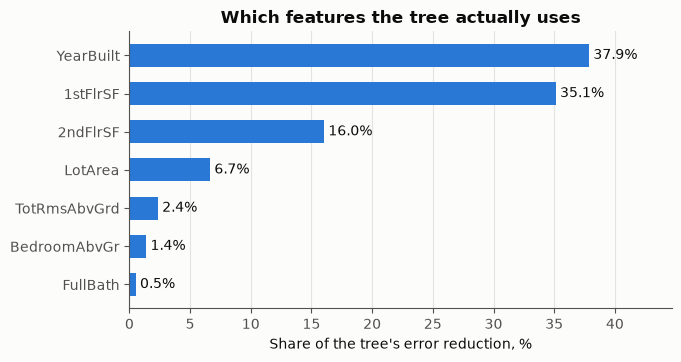

In [16]:
# 8. Chart: which features the tree actually uses
# feature_importances_: each feature's share of the error reduction across all
# the tree's questions; the shares add up to 100%
importance = pd.Series(val_model.feature_importances_, index=feature_names).sort_values() * 100

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(importance.index, importance.values, color=SERIES, height=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in importance.values], padding=3, color=INK)
ax.set_xlim(0, importance.max() * 1.18)   # room for the % labels
ax.set_xlabel("Share of the tree's error reduction, %")
ax.set_title("Which features the tree actually uses")
ax.grid(axis="y", visible=False)
plt.show()

**What this shows:** how much each feature helps *val_model*, as its share of
all the error the tree's questions remove. *YearBuilt* (37.9%) and *1stFlrSF*
(35.1%) do most of the work, then *2ndFlrSF* (16.0%) and *LotArea* (6.7%).
Compare section 3: *FullBath* tracks price strongly (correlation 0.56) and
*TotRmsAbvGrd* too (0.53), yet the tree barely uses them (0.5% and 2.4%).
Bathrooms and rooms mostly follow the house's size and age, so once the tree has
asked about the build year and the floor areas, they add little new. A feature
that moves with the price is not always one the model needs.

# **9. Make Predictions with Validation Data**

In [17]:
# 9. Make Predictions
# Predict with all validation observations
val_predictions = val_model.predict(val_X)

# the predictions at a glance, beside the real prices of the same houses
predicted = pd.Series(val_predictions)
actual = val_y.reset_index(drop=True)
glance = pd.DataFrame([
    ("Houses",                            len(predicted),               len(actual)),
    ("Lowest price, USD",                 predicted.min(),              actual.min()),
    ("Median price, USD",                 predicted.median(),           actual.median()),
    ("Mean price, USD",                   predicted.mean(),             actual.mean()),
    ("Highest price, USD",                predicted.max(),              actual.max()),
    ("Predicted too high",                (predicted > actual).sum(),   None),
    ("Predicted too low",                 (predicted < actual).sum(),   None),
    ("Predicted exactly",                 (predicted == actual).sum(),  None),
    ("Equal to a training house's price", predicted.isin(train_y).sum(), None),
], columns=["Measure", "Predicted", "Actual"])
styled(glance, "The 365 validation predictions at a glance",
       formats={"Predicted": "{:,.0f}", "Actual": "{:,.0f}"}, rules_after=(1, 5, 8))

Measure,Predicted,Actual
Houses,365,365
"Lowest price, USD","60,000","34,900"
"Median price, USD","170,000","166,000"
"Mean price, USD","184,620","184,364"
"Highest price, USD","745,000","755,000"
Predicted too high,179,
Predicted too low,181,
Predicted exactly,5,
Equal to a training house's price,362,


**What this shows:** the 365 prices the model predicted for the validation
houses, beside their real prices. Two things stand out:

* **The tree can only give back prices it has already seen.** 362 of the 365
  predictions are exactly the price of one training house; the other 3 are the
  average of training houses with identical features. A decision tree answers by
  walking down its questions to a leaf and returning the price stored there, so
  it can never predict above the most expensive training house or below the
  cheapest. That is why no prediction is under 60,000, even though one
  validation house sold for 34,900.
* **The model is not biased, it is noisy.** It overprices about as often as it
  underprices (179 too high, 181 too low, only 5 exact), and its average
  prediction (184,620) is within a few hundred of the real average (184,364).
  The misses cancel out on average, but each single house can still be far off;
  section 11 measures how far.

# **10. Compare Predictions with Actual Values**

In [18]:
# 10. Compare
# first five validation houses: predicted vs actual price
comparison = pd.DataFrame({"House": range(1, 6),
                           "Predicted, USD": val_predictions[:5],
                           "Actual, USD": val_y.head().values})
styled(comparison, "First five validation houses: predicted vs actual price")

House,"Predicted, USD","Actual, USD"
1,"82,000","111,000"
2,"126,000","148,000"
3,"62,383","110,000"
4,"206,300","239,799"
5,"118,964","118,858"


**What this shows:** the first five validation houses, which the model never saw
while learning, with the predicted price beside the real one. The estimates are
no longer exact: house 3 is predicted at 62,383 but sold for 110,000, while
house 5 is almost right (118,964 against 118,858). Compare section 6, where
every price matched.

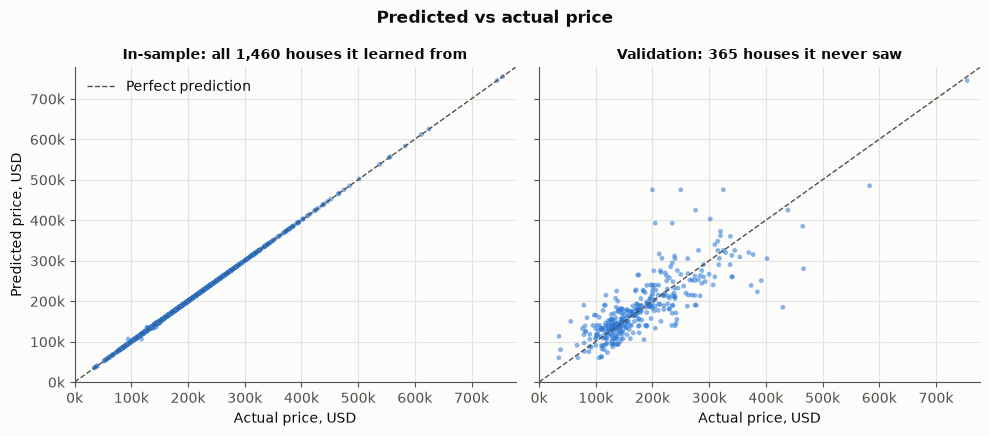

In [19]:
# 10. Chart: predicted vs actual price, in-sample beside validation
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
panels = [(axes[0], y, predictions, "In-sample: all 1,460 houses it learned from"),
          (axes[1], val_y, val_predictions, "Validation: 365 houses it never saw")]
lim = [0, max(y.max(), predictions.max()) * 1.03]
for ax, real, guessed, title in panels:
    ax.plot(lim, lim, color=INK_2, linewidth=1, linestyle="--", label="Perfect prediction")
    ax.scatter(real, guessed, s=12, color=SERIES, alpha=0.55, edgecolors="none")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Actual price, USD")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k")
axes[0].set_ylabel("Predicted price, USD")
axes[0].legend(loc="upper left", frameon=False)
fig.suptitle("Predicted vs actual price", fontweight="bold")
plt.tight_layout()
plt.show()

**What this shows:** each dot is one house, real price across and predicted
price up. On the left (houses the model learned from) every dot sits on the
dashed "perfect prediction" line: the model memorised them. On the right
(houses it never saw) the dots scatter around the line, and that scatter is the
model's real error.

# **11. Calculate Mean Absolute Error**

In [20]:
# 11. Mean Absolute Error
val_mae = mean_absolute_error(val_y, val_predictions)

# for scale: MAE of guessing the training mean for every house
baseline_mae = mean_absolute_error(val_y, [train_y.mean()] * len(val_y))

# the validation MAE, the validation median price and the baseline
mae_summary = pd.DataFrame([
    ("Validation MAE", val_mae),
    ("Validation median price", val_y.median()),
    ("Guess-the-mean MAE", baseline_mae),
], columns=["Measure", "USD"])
styled(mae_summary, "Validation error", formats={"USD": "{:,.0f}"})

Measure,USD
Validation MAE,"33,041"
Validation median price,"166,000"
Guess-the-mean MAE,"59,603"


**What this shows:** the three numbers that judge the model. The validation MAE,
33,041, is how far a prediction is from the real price on average, on houses
the model never saw. Against the median validation price, 166,000, that is
roughly a 20% miss for a typical house. The guess-the-mean MAE, 59,603, is the
error of a "model" that ignores the features and predicts the average training
price for every house. The tree's error is about half of that, so the seven
features really help.

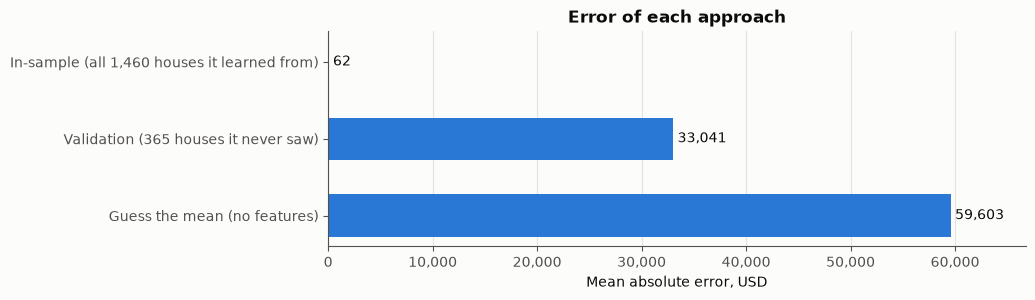

In [21]:
# 11. Chart: error of each approach (lower is better)
# horizontal bars, so each label fits on one line; listed top to bottom
labels = ["In-sample (all 1,460 houses it learned from)",
          "Validation (365 houses it never saw)",
          "Guess the mean (no features)"]
values = [mean_absolute_error(y, predictions), val_mae, baseline_mae]

fig, ax = plt.subplots(figsize=(9, 2.8))
bars = ax.barh(labels[::-1], values[::-1], color=SERIES, height=0.55)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values[::-1]], padding=3, color=INK)
ax.set_xlim(0, max(values) * 1.12)
ax.set_xlabel("Mean absolute error, USD")
ax.set_title("Error of each approach")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="y", visible=False)
plt.show()

**What this shows:** the average error of each approach. The near-zero
in-sample error (62) is misleading, because the model had already seen those
prices. The honest score is the validation error (33,041), which is roughly
half the error of guessing the average price for every house (59,603).

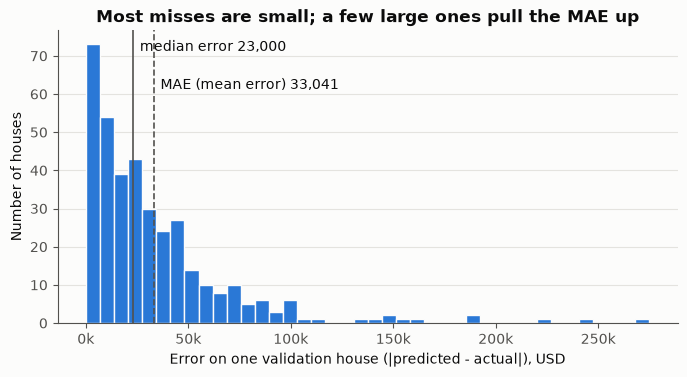

Median validation error: 23000.0 | largest: 275000.0


In [22]:
# 11. Chart: how big each validation error is
errors = (val_predictions - val_y).abs()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(errors, bins=40, color=SERIES, edgecolor=SURFACE, linewidth=1)
for value, name, style, height in [(errors.median(), "median error", "-", 0.93),
                                   (val_mae, "MAE (mean error)", "--", 0.80)]:
    ax.axvline(value, color=INK_2, linewidth=1.2, linestyle=style)
    ax.annotate(f"{name} {value:,.0f}", xy=(value, ax.get_ylim()[1] * height),
                xytext=(5, 0), textcoords="offset points", color=INK)
ax.set_xlabel("Error on one validation house (|predicted - actual|), USD")
ax.set_ylabel("Number of houses")
ax.set_title("Most misses are small; a few large ones pull the MAE up")
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k")
ax.grid(axis="x", visible=False)
plt.show()

print("Median validation error:", errors.median(), "| largest:", errors.max())

**What this shows:** the error on each of the 365 validation houses. Most
misses are small: half are under 23,000 (the median error). A handful of very
large misses, up to 275,000, pull the average (the MAE, 33,041) above the
median.

# **12. Error vs Tree Size**

In [23]:
# 12. Error vs Tree Size
# Refit the tree with a limit on its number of leaves (final answers) and score
# each size on the training houses and on the validation houses
sizes = [5, 10, 25, 50, 100, 250, 500, None]   # None = no limit (the full tree)
rows = []
for max_leaves in sizes:
    sized_model = DecisionTreeRegressor(max_leaf_nodes=max_leaves, random_state=1)
    sized_model.fit(train_X, train_y)
    rows.append({"max_leaf_nodes": max_leaves if max_leaves else "no limit",
                 "leaves": sized_model.get_n_leaves(),
                 "training_MAE": mean_absolute_error(train_y, sized_model.predict(train_X)),
                 "validation_MAE": mean_absolute_error(val_y, sized_model.predict(val_X))})
size_scores = pd.DataFrame(rows)

# the size with the lowest validation MAE is set in bold
best_row = size_scores["validation_MAE"].idxmin()
best = size_scores.loc[best_row]
styled(size_scores.rename(columns={"training_MAE": "Training MAE, USD",
                                   "validation_MAE": "Validation MAE, USD"}),
       f"Error vs tree size: lowest validation MAE {best['validation_MAE']:,.0f} "
       f"with {best['leaves']} leaves (bold)",
       formats={"Training MAE, USD": "{:,.0f}", "Validation MAE, USD": "{:,.0f}"},
       bold_rows=(best_row + 1,))

max_leaf_nodes,leaves,"Training MAE, USD","Validation MAE, USD"
5,5,"35,322","37,558"
10,10,"30,106","33,894"
25,25,"23,838","29,687"
50,50,"19,214","28,501"
100,100,"14,934","28,062"
250,250,"8,380","29,927"
500,500,"3,251","32,077"
no limit,"1,063",71,"33,041"


**What this shows:** each row is the tree retrained with a limit on its number
of leaves (*max_leaf_nodes*); *leaves* is how many it actually grew. With no
limit it grows 1,063, fewer than the 1,417 in section 5, because it learns from
the training houses only. *Training MAE* is the error on the houses it learned
from, *Validation MAE* the error on houses it never saw. Training error keeps
falling as the tree grows, down to 71 with no limit. Validation error falls only
until 100 leaves (28,062, in bold), then rises again to 33,041 with no limit:
past that point the extra leaves memorise single training houses instead of
learning patterns. The chart below draws both columns.

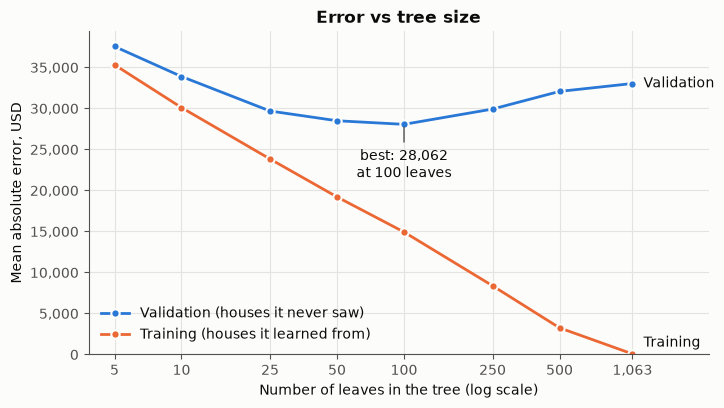

In [24]:
# 12. Chart: error vs tree size (too small underfits, too big overfits)
# one point per distinct tree size, smallest to largest. A limit above the full
# tree's size ends at the same leaf count; keep the last such row, which is the
# "no limit" tree when it is listed last in sizes
plot_scores = (size_scores.sort_values("leaves", kind="stable")
               .drop_duplicates("leaves", keep="last"))

fig, ax = plt.subplots(figsize=(8, 4.2))
for column, name, colour in [("validation_MAE", "Validation (houses it never saw)", SERIES),
                             ("training_MAE", "Training (houses it learned from)", SERIES_2)]:
    ax.plot(plot_scores["leaves"], plot_scores[column], color=colour, linewidth=2,
            marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5, label=name)
    last = plot_scores.iloc[-1]
    ax.annotate(name.split(" (")[0], xy=(last["leaves"], last[column]),
                xytext=(8, 8 if column == "training_MAE" else 0), textcoords="offset points",
                va="center", color=INK)
ax.annotate(f"best: {best['validation_MAE']:,.0f}\nat {best['leaves']} leaves",
            xy=(best["leaves"], best["validation_MAE"]), xytext=(0, -38),
            textcoords="offset points", ha="center", color=INK,
            arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=1))
ax.set_xscale("log")
ax.set_xticks(plot_scores["leaves"], [f"{n:,}" for n in plot_scores["leaves"]])
ax.minorticks_off()
ax.set_xlim(right=plot_scores["leaves"].max() * 2.2)
ax.set_ylim(bottom=0)
ax.set_xlabel("Number of leaves in the tree (log scale)")
ax.set_ylabel("Mean absolute error, USD")
ax.set_title("Error vs tree size")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend(loc="lower left", frameon=False)
plt.show()

**What this shows:** how the error changes as the tree is allowed more leaves
(final answers). Training error (orange) keeps falling toward 0 as the tree
memorises the training houses. Validation error (blue) falls at first, bottoms
out at 28,062 with 100 leaves, then rises again. A tree that is too small
**underfits** (too simple to capture the pattern); one that is too big
**overfits** (it learns noise). The full tree's 33,041 can be beaten simply by
limiting it to about 100 leaves.

# **13. Insights**

**Create Model — same data in and out (sections 1–6)**

* *train-data-pseudonymised.csv* holds 1,460 rows x 7 features in X; all 7
  are integer columns (*LotArea*, *YearBuilt*, *1stFlrSF*, *2ndFlrSF*,
  *FullBath*, *BedroomAbvGr*, *TotRmsAbvGrd*) — no dtypes conversion was
  needed (everything stayed int64). (section 2)
* *YearBuilt* ranges 1872–2010 while *LotArea* is right-skewed: mean
  10,517 vs median 9,478.5, max 215,245. (section 3)
* *SalePrice* (y) ranges 34,900–755,000 with median 163,000; its mode
  is 140,000 (20 homes), runner-up 135,000 (17). (section 1)
* The features carry real signal: *SalePrice* correlates with *1stFlrSF*
  (0.61), *FullBath* (0.56), *TotRmsAbvGrd* (0.53) and *YearBuilt* (0.52),
  less with *2ndFlrSF* (0.32), *LotArea* (0.26) and *BedroomAbvGr* (0.17). (section 3)
* The unpruned DecisionTreeRegressor(random_state=1) grows to depth 23
  with 1,417 leaves for 1,460 samples and memorises the data: 98.4% of rows
  get their exact *SalePrice* back (the rest share identical features with
  a differently priced house), MAE on X itself is 62. That measures
  lookup, not accuracy. (section 5)
* model.predict(X) reproduces the first five y values exactly (151,000,
  184,000, 201,800, 141,000, 252,000) — a test the model has seen the answers
  to. (sections 5 and 6)

**Validate Model — training and validation data kept apart (sections 7–11)**

* train_test_split(random_state=1) keeps 1,095 houses (75%) for training
  and holds back 365 (25%) for validation. (section 7)
* The split is fair (median price 162,000 in training, 166,000 in
  validation), but both extreme houses landed in validation: the cheapest
  (34,900) and the most expensive (755,000) lie outside the 39,300–745,000
  range the model learns from. (section 7)
* val_model memorises its 1,095 training houses as completely as the first
  tree did: 98.5% exact, MAE 71.23 on its own houses. (section 8)
* The tree leans on *YearBuilt* (37.9%) and *1stFlrSF* (35.1%). *FullBath*
  correlates with *SalePrice* at 0.56 yet supplies only 0.5% of the tree's
  error reduction: build year and floor areas already carry that
  information. (sections 3 and 8)
* A tree can only return prices it has seen: 362 of the 365 validation
  predictions equal a training house's price, and none is below 60,000 or
  above 745,000. Its misses are balanced (179 too high, 181 too low), so the
  model is noisy, not biased. (section 9)
* On validation houses the predictions miss: the first five are 82,000,
  126,000, 62,383, 206,300 and 118,964 against real prices 111,000, 148,000,
  110,000, 239,799 and 118,858. (sections 9 and 10)
* Validation MAE is 33,041 — about 20% of the validation median price
  (166,000). The perfect in-sample matches in section 6 said nothing about real
  accuracy. (section 11)
* A model that ignores the features and guesses the average price for
  every house is off by 59,603 on average. The tree is off by 33,041, so
  using the features cuts the error roughly in half. (section 11)

**Tree Size — limiting how big the tree may grow (section 12)**

* With more leaves the training error keeps falling, from 35,322 with 5 leaves
  to 71 with no limit (1,063 leaves): a bigger tree memorises more of the
  houses it learns from. (section 12)
* Validation error does not follow it. It is lowest, 28,062, with 100 leaves;
  smaller trees underfit (37,558 with 5 leaves) and bigger ones overfit
  (33,041 with no limit). (section 12)
* So the simplest improvement is to cap the tree at about 100 leaves: it beats
  the full tree's validation MAE of 33,041 without any new data. (section 12)